# Hartland Quay (Devon) — data, cleaning and the fold axis

Real 3-D outcrop: the folds at Hartland Quay. This notebook turns the raw files
into the data the fitting notebooks use: it cleans the traces and bedding, picks
the traces to fit, sets the modelling frame, and decides the fold axis that the
restore is built around, from stereonets of the bedding. It fits nothing.

| next | reads | does |
|---|---|---|
| `05b_hartland_quay_ldi` | `data/processed/` | the LDI (restore) fit |
| `05c_hartland_quay_surfe` | `results/` from 05b | the Surfe fit |
| `05d_hartland_quay_meshes` | `results/` from 05b | the LDI isosurfaces |
| `05e_hartland_quay_figures` | `results/` | the paper figure |

**Data.** Files in `./data/raw` (z-up metres, `y > −200` m clip,
inconsistent normals removed):

- `hartland_contacts.csv` — digitised polylines (`horizon`, `trace_id`, `x`, `y`, `z`); one trace per horizon
- `hartland_orientations.csv` — bedding (`x`, `y`, `z`, `nx`, `ny`, `nz`); the normal points to younger beds
- `hartland_cloud.npz` — photogrammetry subsample (`xyz`, `rgb`)

**Outputs.** `./data/processed/` (see **Save** at the end), read by the other
notebooks through `hartland_inputs.py`.

## Setup

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics, exploded3d
import figstyle
figstyle.apply()

DATA_DIR = Path("./data/raw")

## Data

Everything is loaded as is, in the frame of the processed files. Traces are
kept in horizon order (`H0`, `H1`, …).

In [2]:
contacts = pd.read_csv(DATA_DIR / "hartland_contacts.csv")
ori = pd.read_csv(DATA_DIR / "hartland_orientations.csv")
cloud = np.load(DATA_DIR / "hartland_cloud.npz")

horizon_names = sorted(contacts["horizon"].unique(), key=lambda s: int(s.lstrip("H")))
traces = [
    contacts.loc[contacts["horizon"] == name, ["x", "y", "z"]].to_numpy(dtype=float)
    for name in horizon_names
]
gp = ori[["x", "y", "z"]].to_numpy(dtype=float)
gv = ori[["nx", "ny", "nz"]].to_numpy(dtype=float)
gv /= np.linalg.norm(gv, axis=1, keepdims=True)
cloud_xyz = np.asarray(cloud["xyz"], dtype=float)
cloud_rgb = np.asarray(cloud["rgb"], dtype=float) / 255.0

n_pts = np.array([len(t) for t in traces])
arc = np.array([np.linalg.norm(np.diff(t, axis=0), axis=1).sum() for t in traces])
print(f"traces {len(traces)}, contact pts {n_pts.sum()} ({n_pts.min()}–{n_pts.max()} per trace)")
print(f"trace length {arc.min():.1f}–{arc.max():.1f} m (median {np.median(arc):.1f} m)")
print(f"orientations {len(gp)}, cloud {len(cloud_xyz)}")
all_xyz = np.vstack([cloud_xyz, gp, *traces])
for ax_name, lo, hi in zip("xyz", all_xyz.min(0), all_xyz.max(0)):
    print(f"{ax_name}: {lo:8.1f} – {hi:8.1f} m")

traces 134, contact pts 38330 (23–1778 per trace)
trace length 4.4–363.8 m (median 44.2 m)
orientations 169, cloud 80000
x:   -101.4 –    177.9 m
y:   -173.0 –    240.6 m
z:    -23.0 –     71.0 m


## Cleaning

Two edits to the measurements themselves.

- **Reversed bedding.** Two readings in the central patch on the platform
  point opposite their neighbours. They were the highest-misfit pair in
  earlier fits, so they are taken out, matched by position.
- **H23 beach legs.** H23 runs along the wave-cut platform and then climbs
  the cliff. Its platform legs (`z ≤ −8` m) are dropped, and the cliff part is
  kept. The other platform traces stay: they give the map view of the folds.

`Z_BEACH` (−8 m in the file frame) is that platform cut. Bedding and the cloud
below it are the platform.

In [3]:
REVERSED_ORI = np.array([
    [50.813842773438, 70.716522216797, -17.513648986816],
    [53.327613830566, 73.135406494141, -17.404697418213],
])
ori_reversed = (np.linalg.norm(gp[:, None] - REVERSED_ORI[None], axis=-1) < 0.05).any(1)
gp_reversed, gv_reversed = gp[ori_reversed], gv[ori_reversed]
gp, gv = gp[~ori_reversed], gv[~ori_reversed]
print(f"dropped {ori_reversed.sum()} reversed bedding readings, {len(gp)} left")

BEACH_TRACE, Z_BEACH = "H23", -8.0
i_beach = horizon_names.index(BEACH_TRACE)
t = traces[i_beach]
beach_pts = t[t[:, 2] <= Z_BEACH]
traces[i_beach] = t[t[:, 2] > Z_BEACH]
print(f"{BEACH_TRACE}: dropped {len(beach_pts)} beach pts (z ≤ {Z_BEACH:g} m), {len(t)} → {len(traces[i_beach])}")

dropped 2 reversed bedding readings, 167 left
H23: dropped 1449 beach pts (z ≤ -8 m), 1778 → 329


## Traces for the fit

No trace is dropped. The digitising is about 0.2 m, and the points of each trace are
thinned so successive points are at least `MIN_SPACING` apart; the ends are kept.
Two pairs are held out of the fit and clubbed, each pair into one trace, as the
test: H22 with H25, and H0 with H7. The test asks whether the two stretches of a
pair lie on one surface. The traces are distinct beds, but their stratigraphic
order is not known.

In [4]:
MIN_SPACING = 2.5  # m, minimum distance between successive points of one trace
TEST_CLUBS = (("H22", "H25"), ("H1", "H7"))  # each pair is one test trace, held out of the fit

def arc_length(t):
    return float(np.linalg.norm(np.diff(t, axis=0), axis=1).sum()) if len(t) > 1 else 0.0


def thin(t, spacing=MIN_SPACING):
    """Points at least `spacing` apart along the trace. The ends are kept."""
    if len(t) < 2:
        return t
    keep, acc = [0], 0.0
    for i in range(1, len(t)):
        acc += float(np.linalg.norm(t[i] - t[i - 1]))
        if acc >= spacing:
            keep.append(i)
            acc = 0.0
    if keep[-1] != len(t) - 1:
        keep.append(len(t) - 1)
    return t[np.asarray(keep)]


all_traces, all_names = list(traces), list(horizon_names)
by_name = dict(zip(all_names, all_traces))
missing = [n for club in TEST_CLUBS for n in club if n not in by_name]
if missing:
    raise KeyError(f"test traces not in the cleaned set: {missing}")
test_members = {n for club in TEST_CLUBS for n in club}


def _closest(a, b):
    step = max(len(a) // 400, 1)
    return float(np.linalg.norm(a[::step, None] - b[None, ::step], axis=2).min())


test_names, test_traces = [], []
for club in TEST_CLUBS:
    parts = [by_name[n] for n in club]
    test_names.append("+".join(club))
    test_traces.append(np.vstack(parts))
    print(f"test {'+'.join(club)}: " + ", ".join(
        f"{n} {arc_length(t):.0f} m" for n, t in zip(club, parts)) +
        f", closest approach {_closest(*parts):.0f} m")

horizon_names = [n for n in all_names if n not in test_members]
traces = [thin(by_name[n]) for n in horizon_names]
test_member_traces = [by_name[n] for n in all_names if n in test_members]
print(f"{len(all_names)} traces, none dropped; {len(traces)} thinned to {MIN_SPACING:g} m "
      f"for the fit ({sum(len(t) for t in traces)} pts), {len(test_names)} held out")

test H22+H25: H22 161 m, H25 120 m, closest approach 32 m
test H1+H7: H1 49 m, H7 150 m, closest approach 45 m
134 traces, none dropped; 130 thinned to 2.5 m for the fit (2724 pts), 2 held out


## Modelling frame

Shift everything to the centroid of the loaded contacts and bedding, so
the Fourier features stay well conditioned in `float32`. The centroid is taken
from all of the loaded data, before cleaning, so this frame is the same one
the earlier Hartland fits used. `origin` is kept to map results back to the
file frame.

In [5]:
origin = np.vstack([contacts[["x", "y", "z"]].to_numpy(dtype=float), ori[["x", "y", "z"]].to_numpy(dtype=float)]).mean(0)
traces = [t - origin for t in traces]
all_traces = [t - origin for t in all_traces]
test_traces = [t - origin for t in test_traces]
test_member_traces = [t - origin for t in test_member_traces]
beach_pts = beach_pts - origin
gp = gp - origin
gp_reversed = gp_reversed - origin
cloud_xyz = cloud_xyz - origin
print(f"origin {origin.round(3)}")
print(f"traces {len(traces)}, contact pts {sum(len(t) for t in traces)}, bedding {len(gp)}")

origin [60.807 62.136 -2.48 ]
traces 130, contact pts 2724, bedding 167


### Fitted and test

Fitted traces are orange. The two test traces, H22 with H25 and H0 with H7, are
purple. H23's beach legs are blue, and the two reversed readings are red with their
recorded way-up. The arrow is the fold hinge.

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


wrote
  figures/supplement/figS_hartland_quay_data.pdf
  figures/supplement/figS_hartland_quay_data.png


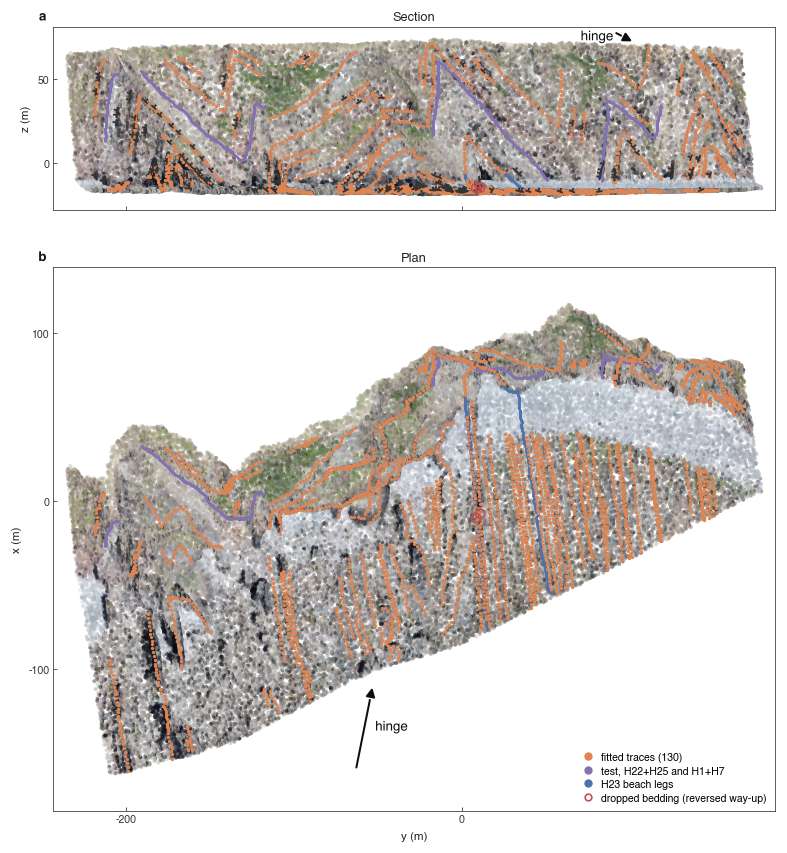

In [6]:
TRACE_COLOR, TEST_COLOR = "#DD8452", "#8172B3"


def section_and_plan(xlim, ylim, zlim, panel=12.0):
    # Section (y–z) above plan (y–x), boxes sized to the data aspect, shared y.
    plot_w, h_sec = figstyle._panel_wh(figstyle.view_aspect(ylim, zlim), panel=panel, min_panel=0.0)   # exactly `panel` wide
    h_plan = plot_w / figstyle.view_aspect(ylim, xlim)
    left, right, bottom, top, row_gap = 0.72, 0.35, 0.52, 0.42, 0.48
    fig_w = left + plot_w + right
    fig_h = bottom + h_plan + row_gap + h_sec + top
    fig = plt.figure(figsize=(fig_w, fig_h), facecolor="white")
    ax_sec = fig.add_axes((left / fig_w, (bottom + h_plan + row_gap) / fig_h, plot_w / fig_w, h_sec / fig_h))
    ax_plan = fig.add_axes((left / fig_w, bottom / fig_h, plot_w / fig_w, h_plan / fig_h), sharex=ax_sec)
    figstyle.set_view(ax_sec, ylim, zlim)
    figstyle.set_view(ax_plan, ylim, xlim)
    figstyle.format_section_ax(ax_sec, xlabel=False, title="Section")
    ax_sec.set_ylabel("z (m)")
    figstyle.panel_label(ax_sec, "a")
    figstyle.format_section_ax(ax_plan, title="Plan")
    ax_plan.set_xlabel("y (m)")
    ax_plan.set_ylabel("x (m)")
    figstyle.panel_label(ax_plan, "b")
    return fig, ax_sec, ax_plan


def draw_hinge(ax_sec, ax_plan, normals):
    # The π-axis. The plan arrow is its trend; the section arrow is the same vector,
    # short because the axis points into the cliff.
    import matplotlib.patheffects as pe

    normals = np.asarray(normals, float)
    _, evecs = np.linalg.eigh(normals.T @ normals)
    h = evecs[:, 0]
    h = h if h[1] >= 0 else -h
    span = abs(ax_plan.get_ylim()[1] - ax_plan.get_ylim()[0])
    length = 0.15 * span / max(float(np.hypot(h[1], h[0])), 1e-6)
    stroke = [pe.withStroke(linewidth=2.8, foreground="white")]

    def arrow(ax, vec, loc, label_side):
        vec = length * np.asarray(vec, float)
        (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
        span_xy = np.array([x1 - x0, y1 - y0])
        tail = np.array([x0, y0]) + np.asarray(loc) * span_xy
        head = tail + vec
        pad = 0.035 * span_xy
        lo, hi = np.array([x0, y0]) + pad, np.array([x1, y1]) - pad
        shift = (np.minimum(0.0, hi - np.maximum(tail, head))
                 + np.maximum(0.0, lo - np.minimum(tail, head)))
        tail, head = tail + shift, head + shift
        ann = ax.annotate(
            "", xy=head, xytext=tail,
            arrowprops=dict(arrowstyle="-|>", color="0.05", lw=1.2,
                            mutation_scale=11, shrinkA=0, shrinkB=0),
            zorder=8,
        )
        ann.arrow_patch.set_path_effects(stroke)
        mid = 0.5 * (tail + head)
        if label_side == "right":
            tx, ha = mid[0] + 0.015 * span_xy[0], "left"
        else:
            tx, ha = mid[0] - 0.015 * span_xy[0], "right"
        ax.text(tx, mid[1], "hinge", ha=ha, va="center", color="0.05", fontsize=8,
                zorder=8, path_effects=stroke)

    arrow(ax_plan, (h[1], h[0]), (0.42, 0.08), "right")
    arrow(ax_sec, (h[1], h[2]), (0.78, 0.97), "left")


def view_limits(pts):
    lo, hi = pts.min(0), pts.max(0)
    pad = np.array([0.08, 0.02, 0.08]) * (hi - lo)
    return tuple(zip(lo - pad, hi + pad))

BEACH_COLOR, REVERSED_COLOR = "#4C72B0", "#C44E52"

xlim, ylim, zlim = view_limits(np.vstack([cloud_xyz, gp]))
fig, ax_sec, ax_plan = section_and_plan(xlim, ylim, zlim, panel=figstyle.PRINT_WIDTH - 1.07)   # 180 mm wide
for ax, j in ((ax_sec, 2), (ax_plan, 0)):
    ax.scatter(cloud_xyz[:, 1], cloud_xyz[:, j], c=cloud_rgb, s=5.2, linewidths=0, alpha=0.5, rasterized=True, zorder=1)
    for t in test_member_traces:
        ax.scatter(t[:, 1], t[:, j], s=1.5, color=TEST_COLOR, linewidths=0, zorder=2)
    ax.scatter(beach_pts[:, 1], beach_pts[:, j], s=1.5, color=BEACH_COLOR, linewidths=0, zorder=2)
    for t in traces:
        ax.scatter(t[:, 1], t[:, j], s=4.0, color=TRACE_COLOR, linewidths=0, zorder=3)
    ax.scatter(gp_reversed[:, 1], gp_reversed[:, j], s=30, facecolors="none", edgecolors=REVERSED_COLOR, linewidths=1.0, zorder=6)
figstyle.draw_younging(ax_sec, gp[:, (1, 2)], gv[:, (1, 2)], quiver_scale=0.22)
figstyle.draw_younging(ax_sec, gp_reversed[:, (1, 2)], gv_reversed[:, (1, 2)], quiver_scale=0.22, color=REVERSED_COLOR)
draw_hinge(ax_sec, ax_plan, gv)
dot = lambda color, label, **kw: plt.Line2D([], [], ls="", marker="o", ms=4, color=color, label=label, **kw)
ax_plan.legend(handles=[dot(TRACE_COLOR, f"fitted traces ({len(traces)})"),
                    dot(TEST_COLOR, "test, H22+H25 and H1+H7"),
                    dot(BEACH_COLOR, "H23 beach legs"),
                    dot("none", "dropped bedding (reversed way-up)", mec=REVERSED_COLOR, mew=1.0)],
           loc="lower right", ncol=1, frameon=False)   # the empty sea in the plan
FIG_DIR = Path("./figures/supplement")
FIG_DIR.mkdir(parents=True, exist_ok=True)
written = figstyle.save(fig, FIG_DIR / "figS_hartland_quay_data")
print("wrote", *written, sep="\n  ")
plt.show()

## Fold axis and hinges

1. **Fold axis.** The π-axis of the bedding: the direction most nearly normal
   to all bedding normals (smallest eigenvector of the normal tensor). Trace
   directions are not used: the dense platform traces are limb strike lines
   and would turn the axis towards the strike of the limbs. The eigenvalues show how cylindrical the
   folds are; a smallest one near zero means the bedding normals lie close to
   one great circle.
2. **Profile.** Every trace is projected onto the plane normal to the axis,
   assuming the folds are cylindrical, as the restore does. Stretches that run
   along the axis (platform traces) carry no profile shape and are dropped.
   That is judged from the trace smoothed over `SMOOTH` m, not per digitised
   segment: the axis points into the cliff, so cliff relief and digitising
   jitter would otherwise chop every cliff trace into pieces. Along-axis gaps
   shorter than `BRIDGE` m stay in the run.
3. **Hinges.** A hinge is a curvature peak of the smoothed profile tangent
   with at least `LIMB_LEN` m of limb on each side, across which the tangent
   turns by at least `HINGE_TURN`. That rejects kinks where a contact crosses
   rough ground. A trace with a hinge is a **fold trace**; the others only mark
   a **contact** along a limb.

In [7]:
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

DS = 0.5               # m, resampling step along each trace
SMOOTH = 2.0           # m, smoothing of trace position and tangent angle
MAX_ALONG_HINGE = 0.5  # |smoothed tangent · hinge| above this runs along the axis
BRIDGE = 3.0           # m, along-axis gaps shorter than this stay in the run
KAPPA_MIN = 0.1        # rad/m, curvature peak that is a hinge candidate
HINGE_GAP = 5.0        # m, closest two hinges on one trace
LIMB_LEN = 5.0         # m of limb needed on each side of a hinge
HINGE_TURN = 45.0      # deg, tangent turn across those limbs for the hinge to count

# Fold axis: π-axis of the bedding, the direction most nearly normal to every
# bedding normal (smallest eigenvector of the normal tensor).
evals, evecs = np.linalg.eigh(gv.T @ gv / len(gv))
hinge = evecs[:, 0]
hinge = hinge if hinge[1] >= 0 else -hinge

# Profile plane: w is "up" projected off the hinge, u completes it (towards +y).
w_ax = np.array([0.0, 0.0, 1.0]) - hinge[2] * hinge
w_ax /= np.linalg.norm(w_ax)
u_ax = np.cross(w_ax, hinge)
u_ax = u_ax if u_ax[1] >= 0 else -u_ax
print(f"hinge {hinge.round(3)}, plunge {np.degrees(np.arcsin(abs(hinge[2]))):.0f}°, "
      f"normal-tensor eigenvalues {evals.round(3)}")


def resample(p, ds=DS):
    # Points every ds along the polyline's arc length.
    s = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(p, axis=0), axis=1))]
    step = np.r_[True, np.diff(s) > 1e-9]
    p, s = p[step], s[step]
    si = np.arange(0.0, s[-1], ds)
    return np.stack([np.interp(si, s, p[:, c]) for c in range(p.shape[1])], axis=1)


def profile_runs(t):
    # Stretches of a trace that cross the folds, projected to the profile and
    # resampled every DS. "Along the axis" is judged from the tangent of the
    # trace smoothed over SMOOTH, so digitising jitter and small cliff relief
    # (which push a trace in x, nearly along the axis) do not split it.
    if arc_length(t) < 4 * SMOOTH:
        return []
    r = resample(t)
    tan = np.gradient(gaussian_filter1d(r, SMOOTH / DS, axis=0, mode="nearest"), axis=0)
    tan /= np.linalg.norm(tan, axis=1, keepdims=True).clip(min=1e-12)
    good = np.abs(tan @ hinge) < MAX_ALONG_HINGE
    gaps = np.flatnonzero(np.diff(np.r_[1, good.astype(int), 1]))
    for a, b in zip(gaps[::2], gaps[1::2]):
        if 0 < a and b < len(good) and (b - a) * DS < BRIDGE:
            good[a:b] = True
    edges = np.flatnonzero(np.diff(np.r_[0, good.astype(int), 0]))
    out = []
    for a, b in zip(edges[::2], edges[1::2]):
        q = r[a:b] @ np.c_[u_ax, w_ax]
        if len(q) < 2 or arc_length(q) < 4 * SMOOTH:
            continue
        out.append(resample(q))
    return out


def tangent_and_hinges(q):
    # Smoothed tangent angle, and the hinges: curvature peaks with a full limb on
    # each side that turn the tangent by at least HINGE_TURN. Kinks from a contact
    # crossing rough ground are short and turn little, so they fail the test.
    d = np.gradient(q, axis=0)
    theta = gaussian_filter1d(np.unwrap(np.arctan2(d[:, 1], d[:, 0])), SMOOTH / DS, mode="nearest")
    kappa = np.abs(np.gradient(theta)) / DS
    peaks, _ = find_peaks(kappa, height=KAPPA_MIN, distance=max(1, int(HINGE_GAP / DS)))
    L = int(round(LIMB_LEN / DS))
    h = [p for p in peaks
         if p - L >= 0 and p + L < len(q) and np.degrees(abs(theta[p + L] - theta[p - L])) >= HINGE_TURN]
    return theta, np.array(h, dtype=int)


# Sweep: which traces show a fold and which are only a contact.
runs = []  # (trace index, profile points, tangent angle, hinge indices)
sweep = []
for k, t in enumerate(all_traces):
    n_hinges, max_turn, prof_len = 0, 0.0, 0.0
    for q in profile_runs(t):
        theta, h = tangent_and_hinges(q)
        runs.append((k, q, theta, h))
        n_hinges += len(h)
        max_turn = max(max_turn, np.degrees(theta.max() - theta.min()))
        prof_len += (len(q) - 1) * DS
    sweep.append(dict(trace=all_names[k], length=arc_length(t), profile_length=prof_len,
                      max_turn=max_turn, hinges=n_hinges))
sweep = pd.DataFrame(sweep)
sweep["role"] = np.where(sweep["hinges"] > 0, "fold",
                         np.where(sweep["profile_length"] > 0, "contact", "along axis"))
fold_traces = set(np.flatnonzero(sweep["role"] == "fold"))
print(sweep["role"].value_counts().to_string())
print(sweep[sweep["role"] == "fold"].sort_values("hinges", ascending=False).round(1).to_string())

hinge [ 0.976  0.195 -0.102], plunge 6°, normal-tensor eigenvalues [0.015 0.443 0.542]
role
along axis    82
contact       42
fold          10
   trace  length  profile_length  max_turn  hinges  role
8     H8   113.5            94.5     137.0       2  fold
25   H25   119.9           105.0     147.2       2  fold
4     H4   103.8            23.5     141.5       1  fold
7     H7   149.7           106.0     137.4       1  fold
13   H13    48.2            21.0      91.7       1  fold
24   H24   111.9            94.0     160.5       1  fold
26   H26    87.9            66.5     142.4       1  fold
27   H27    65.8            56.5     140.8       1  fold
28   H28    93.9            70.5     147.6       1  fold
29   H29    52.0            46.0     155.5       1  fold


### Stereonet

Equal-area (Schmidt) net, lower hemisphere, with the projection from
`diagnostics` (`_schmidt_xy`, `_schmidt_grid`, `_axial_kernel_sum`). Azimuths
are in the modelling frame: +x right, +y up, trend measured from +y towards
+x.

- **(a)** Bedding poles: cliff in orange, beach (wave-cut platform,
  `z ≤ Z_BEACH`) in blue. The two readings dropped for reversed way-up are red
  crosses. Each set has its own π-girdle and π-axis: the cliff and beach
  girdles are dashed, and the solid girdle and black star are all bedding,
  the axis the profile uses.
- **(b)** Density of all bedding poles (an axial kernel of width `BANDWIDTH`,
  so a pole and its opposite count as one), with the π-girdle and axis.

The figure is saved for the supplement as `figures/supplement/figS_hartland_quay_stereonet`.

Two things to read off: do the cliff and beach axes agree, and how much do
the beach readings (about two thirds of the bedding) pull the plunge.

bedding: 62 cliff, 105 beach
 π-axis, all bedding: trend  78.7°, plunge  5.8°,  0.0° from the all-bedding axis, eigenvalues [0.015 0.443 0.542]
       π-axis, cliff: trend  78.4°, plunge 11.8°,  6.0° from the all-bedding axis, eigenvalues [0.026 0.232 0.742]
       π-axis, beach: trend  78.9°, plunge  4.6°,  1.3° from the all-bedding axis, eigenvalues [0.007 0.402 0.591]


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


wrote
  figures/supplement/figS_hartland_quay_stereonet.pdf
  figures/supplement/figS_hartland_quay_stereonet.png


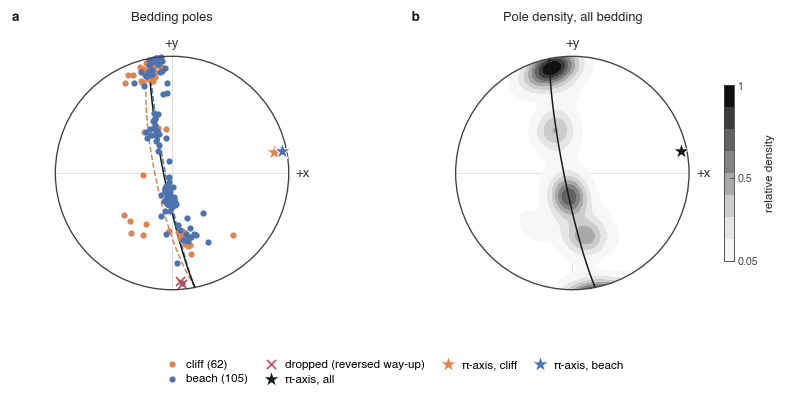

In [8]:
from matplotlib.patches import Circle
import diagnostics

CLIFF_NET_COLOR, BEACH_NET_COLOR, REVERSED_NET_COLOR = "#DD8452", "#4C72B0", "#C44E52"
BANDWIDTH = 8.0  # deg, kernel width of the pole density

on_beach = gp[:, 2] <= Z_BEACH - origin[2]


def pi_axis(normals):
    evals, evecs = np.linalg.eigh(normals.T @ normals / len(normals))
    return evecs[:, 0], evals


def trend_plunge(v):
    # Lower-hemisphere line; trend measured from +y towards +x.
    v = np.asarray(v, dtype=float) / np.linalg.norm(v)
    v = v if v[2] <= 0 else -v
    return np.degrees(np.arctan2(v[0], v[1])) % 360.0, np.degrees(np.arcsin(-v[2]))


def great_circle(normal, n=181):
    # Lower half of the great circle normal to `normal`, projected to the net.
    normal = np.asarray(normal, dtype=float) / np.linalg.norm(normal)
    a = np.cross(normal, [0.0, 0.0, 1.0])
    a = a / np.linalg.norm(a) if np.linalg.norm(a) > 1e-9 else np.array([1.0, 0.0, 0.0])
    b = np.cross(normal, a)
    b = b if b[2] <= 0 else -b
    t = np.linspace(0.0, np.pi, n)[:, None]
    return diagnostics._schmidt_xy(np.cos(t) * a + np.sin(t) * b)


def draw_net(ax, title):
    ax.set_aspect("equal")
    ax.set_xlim(-1.25, 1.25)
    ax.set_ylim(-1.25, 1.25)
    ax.set_axis_off()
    ax.plot([-1, 1], [0, 0], color="0.85", lw=0.5, zorder=0)
    ax.plot([0, 0], [-1, 1], color="0.85", lw=0.5, zorder=0)
    ax.add_patch(Circle((0, 0), 1.0, fill=False, edgecolor="0.25", lw=0.8, zorder=6))
    for s, x, y, ha, va in (("+x", 1.06, 0, "left", "center"), ("+y", 0, 1.06, "center", "bottom")):
        ax.text(x, y, s, ha=ha, va=va, color="0.25", fontsize=8)
    ax.set_title(title, color="0.15")


# Fold axes from the bedding: all of it, the cliff, and the beach.
axis_all, ev_all = pi_axis(gv)
axis_cliff, ev_cliff = pi_axis(gv[~on_beach])
axis_beach, ev_beach = pi_axis(gv[on_beach])

print(f"bedding: {(~on_beach).sum()} cliff, {on_beach.sum()} beach")
for name, v, ev in (("π-axis, all bedding", axis_all, ev_all), ("π-axis, cliff", axis_cliff, ev_cliff),
                    ("π-axis, beach", axis_beach, ev_beach)):
    tr, pl = trend_plunge(v)
    off = np.degrees(np.arccos(min(1.0, abs(v @ axis_all))))
    extra = f", eigenvalues {ev.round(3)}" if ev is not None else ""
    print(f"{name:>20}: trend {tr:5.1f}°, plunge {pl:4.1f}°, {off:4.1f}° from the all-bedding axis{extra}")

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(figstyle.PRINT_WIDTH, 0.47 * figstyle.PRINT_WIDTH), facecolor="white")

# (a) Bedding poles by location.
draw_net(ax_a, "Bedding poles")
for sel, color, label in ((~on_beach, CLIFF_NET_COLOR, "cliff"), (on_beach, BEACH_NET_COLOR, "beach")):
    xy = diagnostics._schmidt_xy(gv[sel])
    ax_a.scatter(xy[:, 0], xy[:, 1], s=14, color=color, linewidths=0, zorder=3, label=f"{label} ({sel.sum()})")
xy = diagnostics._schmidt_xy(gv_reversed)
ax_a.scatter(xy[:, 0], xy[:, 1], s=30, marker="x", color=REVERSED_NET_COLOR, linewidths=1.0, zorder=4,
             label="dropped (reversed way-up)")
for v, color, ls in ((axis_cliff, CLIFF_NET_COLOR, "--"), (axis_beach, BEACH_NET_COLOR, "--"), (axis_all, "0.1", "-")):
    gc = great_circle(v)
    ax_a.plot(gc[:, 0], gc[:, 1], color=color, ls=ls, lw=0.9, zorder=2)
for v, color, marker, label in ((axis_all, "0.1", "*", "π-axis, all"), (axis_cliff, CLIFF_NET_COLOR, "*", "π-axis, cliff"),
                                (axis_beach, BEACH_NET_COLOR, "*", "π-axis, beach")):
    xy = diagnostics._schmidt_xy(v)
    ax_a.scatter(xy[:, 0], xy[:, 1], s=110 if marker == "*" else 40, marker=marker, color=color,
                 edgecolors="white", linewidths=0.6, zorder=7, label=label)
figstyle.panel_label(ax_a, "a")

# (b) Density of all bedding poles (axial kernel, ±n identified) with the π-girdle.
draw_net(ax_b, "Pole density, all bedding")
xx, yy, rr, nn = diagnostics._schmidt_grid(301)
inside = rr <= 1.0
dens = np.full(xx.shape, np.nan)
dens[inside] = diagnostics._axial_kernel_sum(nn[inside], gv, np.ones(len(gv)), 1.0 / np.radians(BANDWIDTH) ** 2)
dens /= np.nanmax(dens)
cf = ax_b.contourf(xx, yy, dens, levels=np.linspace(0.05, 1.0, 9), cmap="Greys", zorder=1)
gc = great_circle(axis_all)
ax_b.plot(gc[:, 0], gc[:, 1], color="0.1", lw=0.9, zorder=2)
xy = diagnostics._schmidt_xy(axis_all)
ax_b.scatter(xy[:, 0], xy[:, 1], s=110, marker="*", color="0.1", edgecolors="white", linewidths=0.6, zorder=7)
cax = ax_b.inset_axes([1.02, 0.2, 0.035, 0.6])     # beside the net, so both nets keep the same size
cbar = fig.colorbar(cf, cax=cax, ticks=[0.05, 0.5, 1.0])
cbar.ax.set_yticklabels(["0.05", "0.5", "1"])
cbar.set_label("relative density")
figstyle.panel_label(ax_b, "b")

fig.legend(*ax_a.get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False, fontsize=7)
fig.subplots_adjust(left=0.02, right=0.9, top=0.9, bottom=0.17, wspace=0.15)
FIG_DIR = Path("./figures/supplement")
FIG_DIR.mkdir(parents=True, exist_ok=True)
written = figstyle.save(fig, FIG_DIR / "figS_hartland_quay_stereonet")
print("wrote", *written, sep="\n  ")
plt.show()

### The fold axis the restore uses

The stereonet settles the choice. The bedding poles lie close to one great
circle, the π-girdle: the smallest eigenvalue of the normal tensor is 0.015 of
the total, so the folds are close to cylindrical and one axis can serve the
whole outcrop. The cliff and beach readings agree on it: their π-axes trend
78.4° and 78.9°, and lie 6.0° and 1.3° from the π-axis of all bedding (trend
78.7°, plunge 5.8°). The cliff readings plunge a little more (11.8° against
4.6°); they are a third of the bedding, so the all-bedding axis sits closer to
the beach axis, but no more than 6° from either.

The restore is built around the **π-axis of all bedding** (black star; `hinge`
above): the fixed potential is the distance along it, and the learnable
potential's wavevectors lie in the plane normal to it. The trend and plunge of
the bedding axes are saved in `settings.json`.

## The test set, and save

Two pairs are held out of the fit and clubbed, each pair into one trace: H22 with
H25, and H0 with H7. Every other cleaned trace is thinned at `MIN_SPACING` and
fitted. The test asks whether the points of a pair lie on one surface.

The bedding is split too. Sorted along the hinge, every `ORI_EVERY`th reading on
the cliff and every `ORI_EVERY`th on the beach is held out, and put back into the
fit if it lies within `ORI_CLEAR` of a reading the fit keeps. The stereonet and
the fold axis above stay on all of the bedding. `gp` and `gv` remain every
cleaned reading; `gp_fit` is what the fits use and `gp_test` is the check.

Everything the fitting notebooks (LDI and Surfe) need goes to
`data/processed/`, in the modelling frame (add `origin` for the file frame).
Ragged polylines are stored as one array plus offsets: polyline `i` is
`xyz[offsets[i]:offsets[i + 1]]`.

- `hartland_processed.npz`
  - the thinned traces for fitting, every cleaned trace at full density,
    and H23's beach legs;
  - the two test traces (`test_trace_*`), each a clubbed pair at full density;
  - the cleaned bedding with a cliff/beach flag, the fit and test split
    (`gp_fit`, `gp_test`), and the dropped reversed readings;
  - the centred photogrammetry cloud;
  - the fold axes with their eigenvalues, the profile axes, and the hinges
    (trace, profile position, tangent angle).
- `trace_sweep.csv` — the role of each trace (fold, contact, along axis).
- `settings.json` — every cleaning and hinge setting, the test pairs, the
  bedding hold-out, and the trend and plunge of each axis.

In [9]:
from scipy.spatial import cKDTree

ORI_EVERY = 4     # along the hinge, on the cliff and on the beach, try every k-th reading
ORI_CLEAR = 5.0   # m, a held-out reading closer than this to a fitted one goes back into the fit

print("test traces:", ", ".join(f"{n} ({len(t)} pts)" for n, t in zip(test_names, test_traces)))

# Test bedding. Candidates are every ORI_EVERY-th reading along the hinge, on the
# cliff and on the beach separately. A candidate is held out only when it is at
# least ORI_CLEAR from every reading the fit keeps, whichever side that reading
# is on. The axis above was taken from all of the bedding.
def _candidates(mask):
    idx = np.flatnonzero(mask)
    order = idx[np.argsort(gp[idx] @ hinge)]
    return set(map(int, order[ORI_EVERY - 1::ORI_EVERY]))

candidate = _candidates(on_beach) | _candidates(~on_beach)
train = [i for i in range(len(gp)) if i not in candidate]
test = []
for i in sorted(candidate, key=lambda i: float(gp[i] @ hinge)):
    dist = float(np.linalg.norm(gp[train] - gp[i], axis=1).min())
    if dist >= ORI_CLEAR:
        test.append(i)
    else:
        train.append(i)
train_i, test_i = np.array(sorted(train)), np.array(sorted(test))
gp_fit, gv_fit, on_beach_fit = gp[train_i], gv[train_i], on_beach[train_i]
gp_test, gv_test, on_beach_test = gp[test_i], gv[test_i], on_beach[test_i]
sep = float(cKDTree(gp_fit).query(gp_test)[0].min())
print(f"bedding {len(gp_fit)} for the fit, {len(gp_test)} held out "
      f"(cliff {(~on_beach_test).sum()}, beach {on_beach_test.sum()}), "
      f"nearest fitted reading {sep:.1f} m")

import json

OUT_DIR = Path("./data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)


def pack(polylines):
    # Ragged polylines as one array plus offsets: polyline i is xyz[off[i]:off[i + 1]].
    return np.vstack(polylines), np.cumsum([0] + [len(p) for p in polylines])


kept_xyz, kept_off = pack(traces)
all_xyz_c, all_off = pack(all_traces)
test_xyz, test_off = pack(test_traces)
hinge_rows = [(all_names[k], q[i], theta[i]) for k, q, theta, h in runs for i in h]

np.savez_compressed(
    OUT_DIR / "hartland_processed.npz",
    origin=origin,
    # traces for fitting: kept and thinned
    trace_names=np.asarray(horizon_names), trace_xyz=kept_xyz, trace_offsets=kept_off,
    # every cleaned trace at full density (H23's beach legs removed)
    all_trace_names=np.asarray(all_names), all_trace_xyz=all_xyz_c, all_trace_offsets=all_off,
    beach_pts=beach_pts,
    # the two clubbed pairs held out of the fit, at full density
    test_trace_names=np.asarray(test_names), test_trace_xyz=test_xyz, test_trace_offsets=test_off,
    # bedding: every cleaned reading, then the fit and the test split
    gp=gp, gv=gv, on_beach=on_beach, gp_reversed=gp_reversed, gv_reversed=gv_reversed,
    gp_fit=gp_fit, gv_fit=gv_fit, on_beach_fit=on_beach_fit,
    gp_test=gp_test, gv_test=gv_test, on_beach_test=on_beach_test,
    cloud_xyz=cloud_xyz.astype(np.float32), cloud_rgb=(cloud_rgb * 255).round().astype(np.uint8),
    # fold axes (unit vectors) and normal-tensor eigenvalues
    hinge=hinge, axis_cliff=axis_cliff, axis_beach=axis_beach,
    eigenvalues_all=ev_all, eigenvalues_cliff=ev_cliff, eigenvalues_beach=ev_beach,
    # fold profile and the hinges found on it
    u_ax=u_ax, w_ax=w_ax,
    fold_trace_names=np.asarray([all_names[k] for k in sorted(fold_traces)]),
    hinge_trace=np.asarray([r[0] for r in hinge_rows]),
    hinge_uw=np.asarray([r[1] for r in hinge_rows]).reshape(-1, 2),
    hinge_theta=np.asarray([r[2] for r in hinge_rows]),
)
sweep.to_csv(OUT_DIR / "trace_sweep.csv", index=False)

settings = dict(
    reversed_bedding=REVERSED_ORI.tolist(), beach_trace=BEACH_TRACE, z_beach=Z_BEACH,
    min_spacing=MIN_SPACING, test_clubs=[list(c) for c in TEST_CLUBS],
    ori_every=ORI_EVERY, ori_clear=ORI_CLEAR,
    ds=DS, smooth=SMOOTH, max_along_hinge=MAX_ALONG_HINGE, bridge=BRIDGE,
    kappa_min=KAPPA_MIN, hinge_gap=HINGE_GAP, limb_len=LIMB_LEN, hinge_turn=HINGE_TURN,
    axes={name: dict(zip(("trend", "plunge"), map(float, trend_plunge(v))))
          for name, v in (("all", axis_all), ("cliff", axis_cliff), ("beach", axis_beach))},
)
(OUT_DIR / "settings.json").write_text(json.dumps(settings, indent=2))
print("wrote", sorted(p.name for p in OUT_DIR.iterdir()), "to", OUT_DIR)

test traces: H22+H25 (1382 pts), H1+H7 (978 pts)
bedding 147 for the fit, 20 held out (cliff 9, beach 11), nearest fitted reading 5.3 m
wrote ['hartland_processed.npz', 'settings.json', 'trace_sweep.csv'] to data/processed
